# SpamShield: Email Spam Detection
**Applied Machine Learning — Final Project** · Astana IT University · Group BDA-2404
**Team:** Alikhan Yessenov, Alua Sarsenova, Arailym Orynbay · **Instructor:** Azim Kassymbayev

## README — how to run this project
1. **Requirements:** Python 3.10+ with `numpy pandas pyarrow scikit-learn matplotlib joblib`
   (`pip install numpy pandas pyarrow scikit-learn matplotlib joblib`).
2. **Run:** open this notebook and choose *Kernel → Restart & Run All*. The first run downloads about 550 MB of public data into `data/raw/`.
   The full run takes about 25 minutes on a laptop CPU (tested on an Apple M3 Pro, 18 GB RAM).
3. **Outputs:** figures in `figures/`, result tables in `results/`, trained models in `models/`.
4. **Data:** TREC 2005 Public Spam Corpus (NIST), CEAS 2008 and Enron-Spam. The data is not redistributed with the project; the notebook downloads it from the original public sources.
5. **Also included:** `disguise_spam.py`, a standalone version of the disguised-spam generator used in Section 8.

**Sections:** 1 Setup · 2 Data · 3 Cleaning · 4 Exploration · 5 Features · 6 Training · 7 Test results · 8 Disguised-spam experiment · 9 Fixing the weakness · 10 Saving

The full discussion of methods and results is in the research paper; this notebook holds the code and its outputs.

## 1. Setup

In [1]:
import copy, email, html, json, random, re, tarfile, time, urllib.request, warnings
from email import policy
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.sparse import vstack
import matplotlib.pyplot as plt
import joblib
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve, log_loss)
import sklearn

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
np.random.seed(SEED)
ROOT = Path.cwd()
RAW, FIG, RES, MOD = ROOT / "data" / "raw", ROOT / "figures", ROOT / "results", ROOT / "models"
for d in (RAW, FIG, RES, MOD):
    d.mkdir(parents=True, exist_ok=True)

# Colors: one fixed color per model and per class, used in every figure
MODEL_COLORS = {"Naive Bayes": "#2a78d6", "Logistic Regression": "#eb6834", "MLP": "#1baf7a"}
CLASS_COLORS = {"Ham": "#6250d6", "Spam": "#e87ba4"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.titlesize": 11,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2b29", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "legend.frameon": False})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.0 | pandas 3.0.3 | numpy 2.4.6


## 2. Data
Three public corpora: **TREC 2005** (NIST), **CEAS 2008** and **Enron-Spam**. The TREC 2007 corpus from our proposal is no longer distributed by NIST, so CEAS 2008 replaces it.

In [2]:
SOURCES = {
    "trec05p-1.tgz": "https://trec.nist.gov/data/spam/trec05p-1.tgz",
    "enron_spam_data.csv": "https://huggingface.co/datasets/SetFit/enron_spam/resolve/main/enron_spam_data.csv",
    "seven/train.parquet": "https://huggingface.co/datasets/K2509118/seven-phishing-email-datasets_pub/resolve/main/train.parquet",
    "seven/eval.parquet": "https://huggingface.co/datasets/K2509118/seven-phishing-email-datasets_pub/resolve/main/eval.parquet",
    "seven/test.parquet": "https://huggingface.co/datasets/K2509118/seven-phishing-email-datasets_pub/resolve/main/test.parquet",
}
for name, url in SOURCES.items():
    path = RAW / name
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        print("downloading", name)
        urllib.request.urlretrieve(url, path)
if not (RAW / "trec05p-1").exists():
    with tarfile.open(RAW / "trec05p-1.tgz") as tar:
        tar.extractall(RAW, filter="data")
print("data ready in", RAW)

data ready in data/raw


In [3]:
def email_to_text(raw_bytes):
    # Return (subject, body) from a raw email; prefer text/plain parts, fall back to text/html
    msg = email.message_from_bytes(raw_bytes, policy=policy.default)
    plain, htmls = [], []
    for part in msg.walk():
        if part.is_multipart() or part.get_content_type() not in ("text/plain", "text/html"):
            continue
        try:
            payload = part.get_payload(decode=True) or b""
            try:
                text = payload.decode(part.get_content_charset() or "latin-1", errors="replace")
            except LookupError:
                text = payload.decode("latin-1", errors="replace")
        except Exception:
            continue
        (plain if part.get_content_type() == "text/plain" else htmls).append(text)
    return str(msg.get("Subject", "") or ""), "\n".join(plain or htmls)

def load_trec(label, rel):
    try:
        subject, body = email_to_text((RAW / "trec05p-1" / "full" / rel).read_bytes())
    except Exception:
        subject, body = "", ""
    return {"source": "TREC 2005", "subject": subject, "body": body, "label": int(label == "spam")}

index = [line.split() for line in (RAW / "trec05p-1" / "full" / "index").read_text().splitlines()]
trec = pd.DataFrame(Parallel(n_jobs=-1, batch_size=500)(delayed(load_trec)(l, r) for l, r in index))

enron_raw = pd.read_csv(RAW / "enron_spam_data.csv")
enron = pd.DataFrame({"source": "Enron-Spam", "subject": enron_raw["Subject"].fillna(""),
                      "body": enron_raw["Message"].fillna(""), "label": (enron_raw["Spam/Ham"] == "spam").astype(int)})

seven = pd.concat([pd.read_parquet(RAW / "seven" / f"{s}.parquet") for s in ("train", "eval", "test")])
ceas_raw = seven[seven["dataset_name"] == "CEAS-08"]
ceas = pd.DataFrame({"source": "CEAS 2008", "subject": ceas_raw["subject"].fillna(""),
                     "body": ceas_raw["text"].fillna(""), "label": ceas_raw["label"].astype(int)})
del seven, ceas_raw, enron_raw

emails = pd.concat([trec, ceas, enron], ignore_index=True)
raw_counts = emails.groupby(["source", "label"]).size().unstack().rename(columns={0: "Ham", 1: "Spam"})
raw_counts["Total"] = raw_counts.sum(axis=1)
raw_counts.loc["All"] = raw_counts.sum()
raw_counts

label,Ham,Spam,Total
source,,,
CEAS 2008,17312,21842,39154
Enron-Spam,16545,17171,33716
TREC 2005,39399,52790,92189
All,73256,91803,165059


## 3. Cleaning
Subject and body are joined, HTML is removed, text is lowercased, every number becomes the token `num`, and all other non-letters become spaces. Emails with fewer than 3 words, emails whose identical text appears with both labels, and exact duplicates are dropped.

In [4]:
RE_BLOCK = re.compile(r"<(script|style)[^>]*>.*?</\1>", re.S | re.I)
RE_TAG = re.compile(r"<[^>]{0,500}>")
RE_NUM, RE_NONALPHA, RE_SPACE = re.compile(r"\d+"), re.compile(r"[^a-z\s]"), re.compile(r"\s+")
MAX_CHARS = 20000

def clean(text):
    text = RE_TAG.sub(" ", RE_BLOCK.sub(" ", text[:MAX_CHARS * 3]))
    text = RE_NONALPHA.sub(" ", RE_NUM.sub(" num ", html.unescape(text).lower()))
    return RE_SPACE.sub(" ", text).strip()[:MAX_CHARS]

emails["text"] = (emails["subject"] + " " + emails["body"]).map(clean)
emails["n_words"] = emails["text"].str.split().str.len()

steps = [("Raw emails", len(emails))]
emails = emails[emails["n_words"] >= 3]
steps.append(("After removing empty / <3 words", len(emails)))
n_labels = emails.groupby("text")["label"].nunique()
emails = emails[~emails["text"].isin(n_labels[n_labels > 1].index)]
steps.append(("After removing conflicting labels", len(emails)))
emails = emails.drop_duplicates("text").reset_index(drop=True)
steps.append(("After removing duplicates (final)", len(emails)))
cleaning_steps = pd.DataFrame(steps, columns=["Step", "Emails"])
print(cleaning_steps.to_string(index=False))
clean_counts = emails.groupby(["source", "label"]).size().unstack().rename(columns={0: "Ham", 1: "Spam"})
clean_counts["Total"] = clean_counts.sum(axis=1)
clean_counts.loc["All"] = clean_counts.sum()
clean_counts

                             Step  Emails
                       Raw emails  165059
  After removing empty / <3 words  161804
After removing conflicting labels  161666
After removing duplicates (final)  122850


label,Ham,Spam,Total
source,,,
CEAS 2008,17134,18652,35786
Enron-Spam,12460,13763,26223
TREC 2005,31714,29127,60841
All,61308,61542,122850


## 4. Exploration

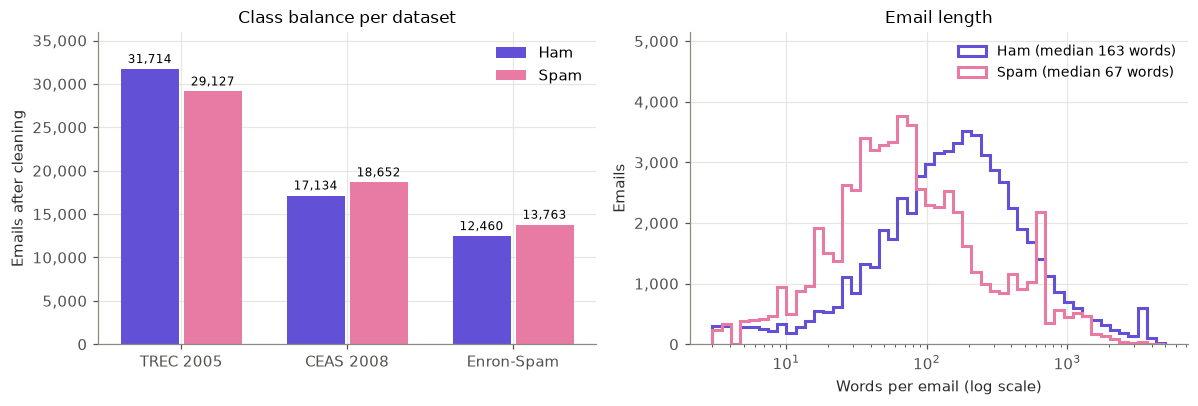

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Ham,61308.0,313.3,502.9,3.0,73.0,163.0,333.0,5026.0
Spam,61542.0,173.6,296.4,3.0,33.0,67.0,156.0,4906.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
order = ["TREC 2005", "CEAS 2008", "Enron-Spam"]
x = np.arange(len(order)); w = 0.38
for i, (cls, col) in enumerate([("Ham", 0), ("Spam", 1)]):
    vals = [((emails["source"] == s) & (emails["label"] == col)).sum() for s in order]
    bars = axes[0].bar(x + (i - 0.5) * w, vals, w - 0.03, color=CLASS_COLORS[cls], label=cls)
    axes[0].bar_label(bars, labels=[f"{v:,}" for v in vals], fontsize=8, padding=2)
axes[0].set_xticks(x, order); axes[0].set_ylabel("Emails after cleaning"); axes[0].legend()
axes[0].set_ylim(0, axes[0].get_ylim()[1] * 1.08)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].set_title("Class balance per dataset")

bins = np.logspace(np.log10(3), np.log10(5000), 50)
for cls, col in [("Ham", 0), ("Spam", 1)]:
    axes[1].hist(emails.loc[emails["label"] == col, "n_words"], bins=bins, histtype="step", lw=2,
                 color=CLASS_COLORS[cls], label=f"{cls} (median {emails.loc[emails['label'] == col, 'n_words'].median():.0f} words)")
axes[1].set_xscale("log"); axes[1].set_xlabel("Words per email (log scale)"); axes[1].set_ylabel("Emails")
axes[1].set_ylim(0, axes[1].get_ylim()[1] * 1.3); axes[1].legend(loc="upper right", fontsize=9); axes[1].set_title("Email length")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
fig.tight_layout(); save(fig, "fig_eda")
emails.groupby("label")["n_words"].describe().rename(index={0: "Ham", 1: "Spam"}).round(1)

## 5. Train / validation / test split and TF-IDF features
Stratified 70 / 15 / 15 split by dataset and label. TF-IDF is fitted on the training set only.

In [6]:
strata = emails["source"] + "_" + emails["label"].astype(str)
train_df, rest_df = train_test_split(emails, test_size=0.30, stratify=strata, random_state=SEED)
val_df, test_df = train_test_split(rest_df, test_size=0.50, stratify=strata.loc[rest_df.index], random_state=SEED)
split_table = pd.DataFrame({"Emails": [len(d) for d in (train_df, val_df, test_df)],
                            "Spam share": [d["label"].mean().round(3) for d in (train_df, val_df, test_df)]},
                           index=["Train", "Validation", "Test"])

t0 = time.time()
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9, max_features=50_000,
                             sublinear_tf=True, dtype=np.float32)
X_train = vectorizer.fit_transform(train_df["text"])
X_val, X_test = vectorizer.transform(val_df["text"]), vectorizer.transform(test_df["text"])
y_train, y_val, y_test = train_df["label"].values, val_df["label"].values, test_df["label"].values
print(f"TF-IDF matrix: {X_train.shape[0]:,} x {X_train.shape[1]:,} features, "
      f"{X_train.nnz / X_train.shape[0]:.0f} non-zero values per email, built in {time.time() - t0:.0f} s")
split_table

TF-IDF matrix: 85,995 x 50,000 features, 184 non-zero values per email, built in 21 s


,Emails,Spam share
Train,85995,0.501
Validation,18427,0.501
Test,18428,0.501


## 6. Training and hyperparameter selection
Each model's settings are chosen by F1 on the **validation** set. The test set is not used here.

In [7]:
def scores(y_true, p_spam, threshold=0.5):
    y_pred = (p_spam >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y_true, y_pred), "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred), "F1": f1_score(y_true, y_pred),
            "ROC-AUC": roc_auc_score(y_true, p_spam) if len(set(y_true)) > 1 else np.nan,
            "PR-AUC": average_precision_score(y_true, p_spam) if len(set(y_true)) > 1 else np.nan,
            "FPR (ham flagged)": fp / (fp + tn) if (fp + tn) else np.nan}

# Naive Bayes: smoothing alpha
nb_grid = []
for a in [0.001, 0.01, 0.1, 0.5, 1.0]:
    m = MultinomialNB(alpha=a).fit(X_train, y_train)
    nb_grid.append({"alpha": a, "val_F1": f1_score(y_val, m.predict(X_val))})
nb_grid = pd.DataFrame(nb_grid); best_alpha = nb_grid.loc[nb_grid["val_F1"].idxmax(), "alpha"]

# Logistic Regression: inverse regularization strength C
lr_grid = []
for C in [0.1, 1, 10, 100]:
    m = LogisticRegression(C=C, max_iter=3000).fit(X_train, y_train)
    lr_grid.append({"C": C, "val_F1": f1_score(y_val, m.predict(X_val))})
lr_grid = pd.DataFrame(lr_grid); best_C = lr_grid.loc[lr_grid["val_F1"].idxmax(), "C"]

t0 = time.time(); nb = MultinomialNB(alpha=best_alpha).fit(X_train, y_train); nb_time = time.time() - t0
t0 = time.time(); lr = LogisticRegression(C=best_C, max_iter=3000).fit(X_train, y_train); lr_time = time.time() - t0
print(f"Best Naive Bayes alpha = {best_alpha} (fit {nb_time:.1f} s) | best Logistic Regression C = {best_C} (fit {lr_time:.1f} s)")
pd.concat([nb_grid.round(4), lr_grid.round(4)], axis=1, keys=["Naive Bayes", "Logistic Regression"])

Best Naive Bayes alpha = 0.001 (fit 0.1 s) | best Logistic Regression C = 10.0 (fit 1.2 s)


Naive Bayes         Logistic Regression        
        alpha  val_F1                   C  val_F1
0       0.001  0.9658                 0.1  0.9675
1       0.010  0.9653                 1.0  0.9809
2       0.100  0.9644                10.0  0.9848
3       0.500  0.9637               100.0  0.9830
4       1.000  0.9628                 NaN     NaN

In [8]:
def train_mlp(hidden, alpha, X, y, X_v=None, y_v=None, max_epochs=12, patience=2, fixed_epochs=None, seed=SEED):
    # One-hidden-layer MLP trained epoch by epoch (Adam, mini-batches of 256) with early stopping on validation loss
    mlp = MLPClassifier(hidden_layer_sizes=(hidden,), activation="relu", solver="adam", alpha=alpha,
                        batch_size=256, learning_rate_init=1e-3, random_state=seed)
    rng = np.random.RandomState(seed)
    probe = rng.choice(X.shape[0], min(20_000, X.shape[0]), replace=False)   # fixed sample for train loss
    history, best, best_loss, wait = [], None, np.inf, 0
    for epoch in range(1, (fixed_epochs or max_epochs) + 1):
        order = rng.permutation(X.shape[0])
        for s in range(0, len(order), 8192):
            idx = order[s:s + 8192]
            mlp.partial_fit(X[idx], y[idx], classes=[0, 1])
        p_tr = mlp.predict_proba(X[probe])[:, 1]
        row = {"epoch": epoch, "train_loss": log_loss(y[probe], p_tr), "train_F1": f1_score(y[probe], p_tr >= 0.5)}
        if X_v is not None:
            p_v = mlp.predict_proba(X_v)[:, 1]
            row.update(val_loss=log_loss(y_v, p_v), val_F1=f1_score(y_v, p_v >= 0.5))
        history.append(row)
        if fixed_epochs:
            continue
        if row["val_loss"] < best_loss - 1e-4:
            best, best_loss, wait = copy.deepcopy(mlp), row["val_loss"], 0
        else:
            wait += 1
            if wait >= patience:
                break
    return (best or mlp), pd.DataFrame(history)

mlp_runs = {}
for hidden in [64, 128, 256]:
    t0 = time.time()
    model, hist = train_mlp(hidden, 1e-4, X_train, y_train, X_val, y_val)
    best_row = hist.loc[hist["val_loss"].idxmin()]
    mlp_runs[hidden] = {"model": model, "history": hist, "time": time.time() - t0,
                        "best_epoch": int(best_row["epoch"]), "val_F1": best_row["val_F1"]}
    print(f"hidden={hidden:3d}: best epoch {int(best_row['epoch'])}, val F1 {best_row['val_F1']:.4f}, "
          f"val loss {best_row['val_loss']:.4f}, {time.time() - t0:.0f} s")

best_hidden = max(mlp_runs, key=lambda h: mlp_runs[h]["val_F1"])
mlp, mlp_hist, mlp_time = mlp_runs[best_hidden]["model"], mlp_runs[best_hidden]["history"], mlp_runs[best_hidden]["time"]
print(f"Selected MLP: 1 hidden layer of {best_hidden} ReLU units, early-stopped at epoch {mlp_runs[best_hidden]['best_epoch']}")

hidden= 64: best epoch 4, val F1 0.9869, val loss 0.0381, 46 s


hidden=128: best epoch 3, val F1 0.9864, val loss 0.0387, 83 s


hidden=256: best epoch 2, val F1 0.9866, val loss 0.0395, 132 s
Selected MLP: 1 hidden layer of 64 ReLU units, early-stopped at epoch 4


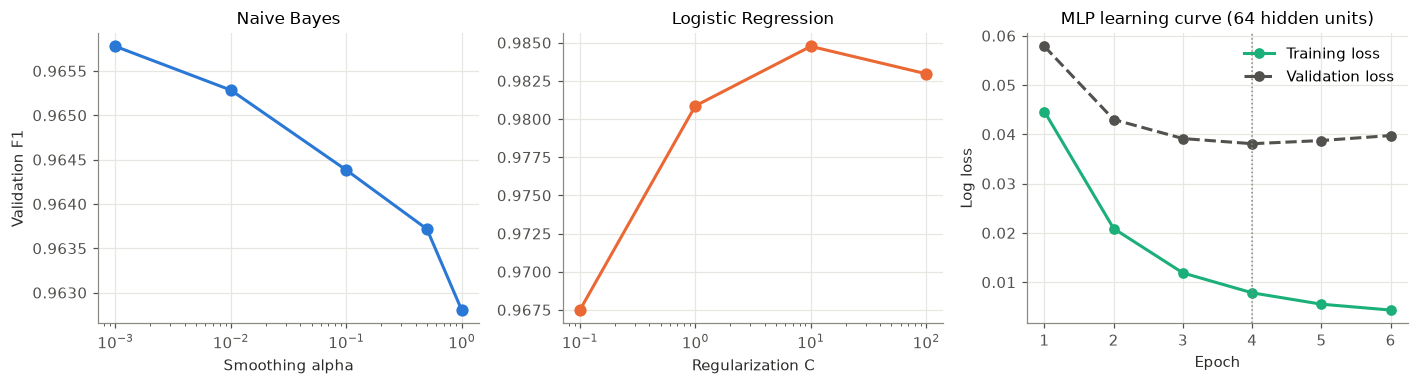

,best epoch,val F1,time (s)
hidden units,,,
64,4.0,0.9869,46.0
128,3.0,0.9864,83.0
256,2.0,0.9866,132.0


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(nb_grid["alpha"], nb_grid["val_F1"], "o-", color=MODEL_COLORS["Naive Bayes"], lw=2, ms=7)
axes[0].set_xscale("log"); axes[0].set_xlabel("Smoothing alpha"); axes[0].set_ylabel("Validation F1")
axes[0].set_title("Naive Bayes")
axes[1].plot(lr_grid["C"], lr_grid["val_F1"], "o-", color=MODEL_COLORS["Logistic Regression"], lw=2, ms=7)
axes[1].set_xscale("log"); axes[1].set_xlabel("Regularization C"); axes[1].set_title("Logistic Regression")
h = mlp_hist
axes[2].plot(h["epoch"], h["train_loss"], "o-", color=MODEL_COLORS["MLP"], lw=2, ms=6, label="Training loss")
axes[2].plot(h["epoch"], h["val_loss"], "o--", color="#52514e", lw=2, ms=6, label="Validation loss")
axes[2].axvline(mlp_runs[best_hidden]["best_epoch"], color="#8a8984", lw=1, ls=":")
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Log loss"); axes[2].legend()
axes[2].set_title(f"MLP learning curve ({best_hidden} hidden units)")
fig.tight_layout(); save(fig, "fig_tuning")
pd.DataFrame({h: {"best epoch": r["best_epoch"], "val F1": round(r["val_F1"], 4), "time (s)": round(r["time"])}
              for h, r in mlp_runs.items()}).T.rename_axis("hidden units")

## 7. Test-set results
The test set is used once, with the settings chosen above. Threshold = 0.5.

In [10]:
models = {"Naive Bayes": nb, "Logistic Regression": lr, "MLP": mlp}
fit_times = {"Naive Bayes": nb_time, "Logistic Regression": lr_time, "MLP": mlp_time}
test_proba, rows = {}, []
for name, m in models.items():
    t0 = time.time(); test_proba[name] = m.predict_proba(X_test)[:, 1]; pred_time = time.time() - t0
    rows.append({"Model": name, **scores(y_test, test_proba[name]), "Train time (s)": fit_times[name],
                 "Predict time (ms / 1k emails)": 1000 * pred_time / len(y_test) * 1000})
baseline = {"Model": "Always 'spam' baseline", **scores(y_test, np.ones(len(y_test))), "Train time (s)": 0,
            "Predict time (ms / 1k emails)": 0}
test_results = pd.DataFrame(rows + [baseline]).set_index("Model")
test_results.to_csv(RES / "test_results.csv")
test_results.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,FPR (ham flagged),Train time (s),Predict time (ms / 1k emails)
Model,,,,,,,,,
Naive Bayes,0.9673,0.9870,0.9472,0.9667,0.9965,0.9966,0.0125,0.0611,0.9917
Logistic Regression,0.9844,0.9816,0.9874,0.9845,0.9985,0.9986,0.0186,1.1641,0.1903
MLP,0.9866,0.9848,0.9885,0.9866,0.9989,0.9990,0.0153,46.4776,1.8231
Always 'spam' baseline,0.5010,0.5010,1.0000,0.6675,0.5000,0.5010,1.0000,0.0000,0.0000


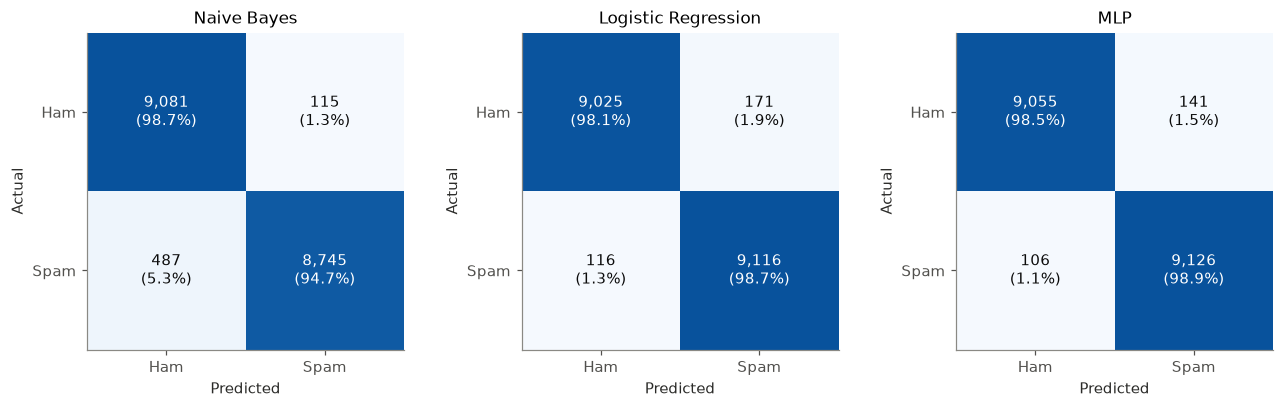

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
for ax, (name, p) in zip(axes, test_proba.items()):
    cm = confusion_matrix(y_test, p >= 0.5)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.15)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() * 0.5 else "#0b0b0b", fontsize=10)
    ax.set_xticks([0, 1], ["Ham", "Spam"]); ax.set_yticks([0, 1], ["Ham", "Spam"]); ax.grid(False)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(name)
fig.tight_layout(); save(fig, "fig_confusion")

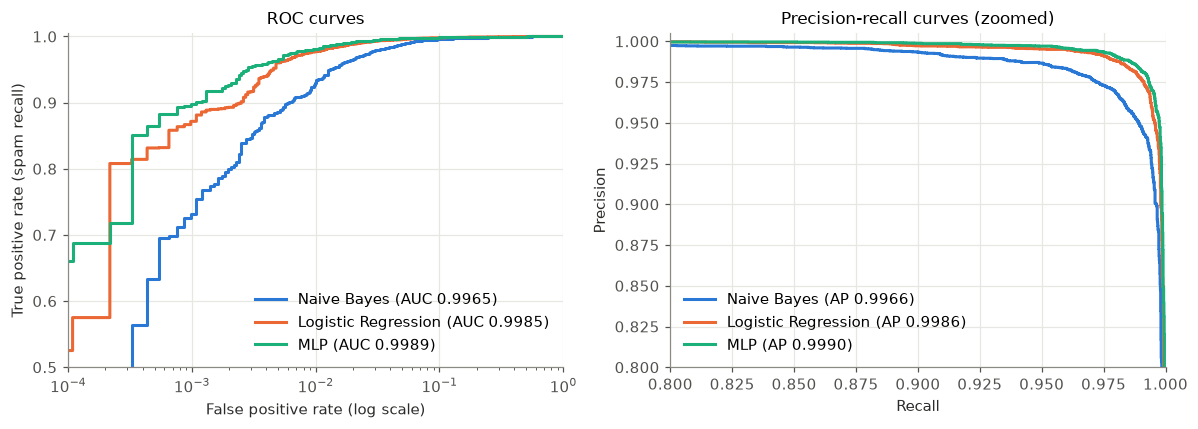

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[name], lw=2, label=f"{name} (AUC {roc_auc_score(y_test, p):.4f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=MODEL_COLORS[name], lw=2, label=f"{name} (AP {average_precision_score(y_test, p):.4f})")
axes[0].set_xscale("log"); axes[0].set_xlim(1e-4, 1); axes[0].set_ylim(0.5, 1.005)
axes[0].set_xlabel("False positive rate (log scale)"); axes[0].set_ylabel("True positive rate (spam recall)")
axes[0].set_title("ROC curves"); axes[0].legend(loc="lower right")
axes[1].set_xlim(0.8, 1.0); axes[1].set_ylim(0.8, 1.005)
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-recall curves (zoomed)")
axes[1].legend(loc="lower left")
fig.tight_layout(); save(fig, "fig_roc_pr")

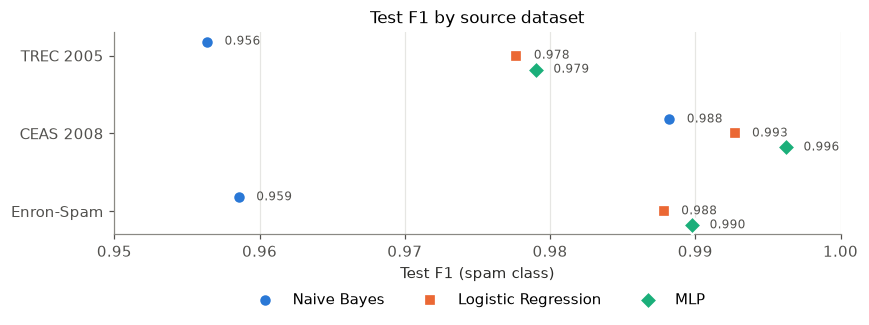

F1                       FPR (ham flagged)  \
Model      Logistic Regression     MLP Naive Bayes Logistic Regression   
Dataset                                                                  
CEAS 2008               0.9927  0.9963      0.9882              0.0136   
Enron-Spam              0.9878  0.9898      0.9586              0.0080   
TREC 2005               0.9777  0.9790      0.9564              0.0254   

                                
Model          MLP Naive Bayes  
Dataset                         
CEAS 2008   0.0066      0.0140  
Enron-Spam  0.0070      0.0048  
TREC 2005   0.0233      0.0147

In [13]:
src_rows = []
for src in order:
    mask = (test_df["source"] == src).values
    for name, p in test_proba.items():
        s = scores(y_test[mask], p[mask])
        src_rows.append({"Dataset": src, "Model": name, "F1": s["F1"], "FPR (ham flagged)": s["FPR (ham flagged)"],
                         "Recall": s["Recall"], "Emails": mask.sum()})
by_source = pd.DataFrame(src_rows)
by_source.to_csv(RES / "test_by_source.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.2))
markers = {"Naive Bayes": "o", "Logistic Regression": "s", "MLP": "D"}
for i, name in enumerate(models):
    d = by_source[by_source["Model"] == name]
    ax.scatter(d["F1"], np.arange(3) + (i - 1) * 0.18, s=70, marker=markers[name], color=MODEL_COLORS[name],
               edgecolor="white", linewidth=1.5, zorder=3, label=name)
    for v, y in zip(d["F1"], np.arange(3) + (i - 1) * 0.18):
        ax.text(v + 0.0012, y, f"{v:.3f}", va="center", fontsize=8, color="#52514e")
ax.set_yticks(np.arange(3), order); ax.invert_yaxis(); ax.set_xlim(0.95, 1.0)
ax.set_xlabel("Test F1 (spam class)"); ax.set_title("Test F1 by source dataset"); ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3)
fig.tight_layout(); save(fig, "fig_by_source")
by_source.pivot(index="Dataset", columns="Model", values=["F1", "FPR (ham flagged)"]).round(4)

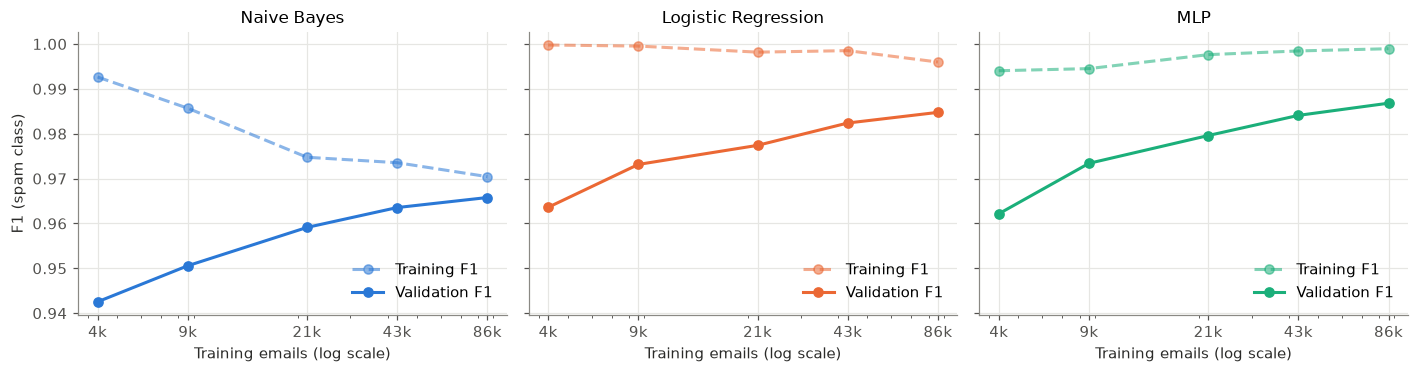

Model,Logistic Regression,MLP,Naive Bayes
Training emails,,,
4299,0.9636,0.9621,0.9425
8599,0.9732,0.9734,0.9506
21498,0.9774,0.9796,0.9591
42997,0.9824,0.9841,0.9635
85995,0.9848,0.9868,0.9658


In [14]:
# Learning curve over training-set size (scores on the validation set)
size_rows = []
rng = np.random.RandomState(SEED)
for frac in [0.05, 0.1, 0.25, 0.5, 1.0]:
    idx = rng.choice(X_train.shape[0], int(frac * X_train.shape[0]), replace=False)
    Xs, ys = X_train[idx], y_train[idx]
    fitted = {"Naive Bayes": MultinomialNB(alpha=best_alpha).fit(Xs, ys),
              "Logistic Regression": LogisticRegression(C=best_C, max_iter=3000).fit(Xs, ys),
              "MLP": train_mlp(best_hidden, 1e-4, Xs, ys, fixed_epochs=mlp_runs[best_hidden]["best_epoch"])[0]}
    for name, m in fitted.items():
        size_rows.append({"Model": name, "Training emails": len(idx),
                          "Train F1": f1_score(ys, m.predict(Xs)), "Validation F1": f1_score(y_val, m.predict(X_val))})
size_curve = pd.DataFrame(size_rows)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, name in zip(axes, models):
    d = size_curve[size_curve["Model"] == name]
    ax.plot(d["Training emails"], d["Train F1"], "o--", color=MODEL_COLORS[name], lw=2, ms=6, alpha=0.55, label="Training F1")
    ax.plot(d["Training emails"], d["Validation F1"], "o-", color=MODEL_COLORS[name], lw=2, ms=6, label="Validation F1")
    ax.set_xscale("log"); ax.set_xlabel("Training emails (log scale)"); ax.set_title(name); ax.legend(loc="lower right")
    ax.set_xticks(d["Training emails"].values, [f"{v / 1000:.0f}k" for v in d["Training emails"].values])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
axes[0].set_ylabel("F1 (spam class)")
fig.tight_layout(); save(fig, "fig_size_curve")
size_curve.pivot(index="Training emails", columns="Model", values="Validation F1").round(4)

In [15]:
# Lower false-positive rate: pick the threshold on VALIDATION ham, then check it on the test set
thr_rows = []
for name, m in models.items():
    p_val_ham = m.predict_proba(X_val[y_val == 0])[:, 1]
    for target in [0.01, 0.005, 0.001]:
        thr = float(np.quantile(p_val_ham, 1 - target))
        s = scores(y_test, test_proba[name], threshold=thr)
        thr_rows.append({"Model": name, "Target FPR": target, "Threshold": thr, "Test FPR": s["FPR (ham flagged)"],
                         "Test recall": s["Recall"], "Test F1": s["F1"]})
thresholds = pd.DataFrame(thr_rows)
thresholds.to_csv(RES / "threshold_results.csv", index=False)
thresholds.round(4)

,Model,Target FPR,Threshold,Test FPR,Test recall,Test F1
0,Naive Bayes,0.010,0.4975,0.0125,0.9476,0.9669
1,Naive Bayes,0.005,0.7463,0.0054,0.8929,0.9407
2,Naive Bayes,0.001,0.9836,0.0011,0.7421,0.8514
3,Logistic Regression,0.010,0.6998,0.0091,0.9758,0.9832
4,Logistic Regression,0.005,0.8411,0.0046,0.9511,0.9727
5,Logistic Regression,0.001,0.9682,0.0007,0.8450,0.9157
6,MLP,0.010,0.6700,0.0112,0.9830,0.9859
7,MLP,0.005,0.8723,0.0048,0.9630,0.9788
8,MLP,0.001,0.9883,0.0005,0.8803,0.9361


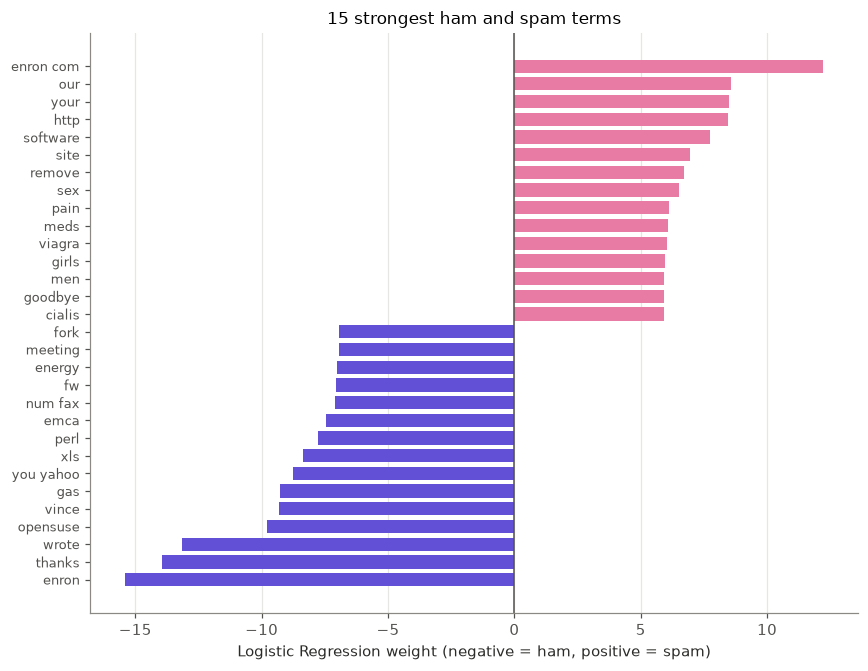

In [16]:
# Most influential words (Logistic Regression weights)
vocab = np.array(vectorizer.get_feature_names_out())
coef = lr.coef_[0]
top_spam, top_ham = np.argsort(coef)[-15:], np.argsort(coef)[:15]
fig, ax = plt.subplots(figsize=(8, 6.2))
idx = np.concatenate([top_ham, top_spam])
ax.barh(np.arange(30), coef[idx], color=[CLASS_COLORS["Ham"]] * 15 + [CLASS_COLORS["Spam"]] * 15, height=0.75)
ax.set_yticks(np.arange(30), vocab[idx], fontsize=8.5); ax.axvline(0, color="#52514e", lw=1)
ax.set_xlabel("Logistic Regression weight (negative = ham, positive = spam)")
ax.set_title("15 strongest ham and spam terms"); ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "fig_top_words")

In [17]:
# Where does the best model fail? Errors by dataset and email length
best_name = test_results.drop(index="Always 'spam' baseline")["F1"].idxmax()
err = test_df[["source", "label", "n_words"]].copy()
err["pred"] = (test_proba[best_name] >= 0.5).astype(int)
err["length"] = pd.cut(err["n_words"], [0, 20, 50, 200, 1000, 1e9], labels=["<20", "20-50", "50-200", "200-1000", ">1000"])
err["error"] = np.where((err["label"] == 0) & (err["pred"] == 1), "False positive (ham → spam)",
               np.where((err["label"] == 1) & (err["pred"] == 0), "False negative (missed spam)", "Correct"))
print("Best model on test F1:", best_name)
error_table = pd.crosstab(err["length"], err["error"], normalize="index").mul(100).round(2)
error_table.to_csv(RES / "errors_by_length.csv")
error_table

Best model on test F1: MLP


error,Correct,False negative (missed spam),False positive (ham → spam)
length,,,
<20,94.09,1.78,4.12
20-50,99.43,0.24,0.33
50-200,99.26,0.33,0.41
200-1000,98.83,0.71,0.47
>1000,99.00,0.75,0.25


## 8. Disguised-spam experiment
We change only the **spam** emails in the test set and measure how much each model's spam recall drops. The trained models and vectorizer stay the same.

Attacks: **leet** (`free` → `fr3e`) and **spacing** (`free` → `f r e e`) applied to the 50 most spam-typical words, **generic padding** (30 everyday office words appended), **informed padding** (30 of the most ham-like words in the training data appended), and **combined** (leet or spacing on spam words plus informed padding).

In [18]:
# Spam words to disguise and ham words for padding, chosen from the TRAINING set only:
# words that appear in at least 3% of one class, ranked by how much more often they appear there than in the other class
cv = CountVectorizer(binary=True, min_df=200, token_pattern=r"\b[a-z]{3,}\b")
B = cv.fit_transform(train_df["text"]); words = np.array(cv.get_feature_names_out())
rate_spam = np.asarray(B[y_train == 1].sum(0)).ravel() / (y_train == 1).sum()
rate_ham = np.asarray(B[y_train == 0].sum(0)).ravel() / (y_train == 0).sum()
log_ratio = np.log((rate_spam + 1e-4) / (rate_ham + 1e-4))
def top_words(rate, sign, k):
    ok = np.where((rate >= 0.03) & (words != "num"))[0]
    return list(words[ok[np.argsort(sign * log_ratio[ok])[::-1][:k]]])
SPAM_WORDS, HAM_WORDS = top_words(rate_spam, 1, 50), top_words(rate_ham, -1, 30)
GENERIC_WORDS = ["meeting", "project", "thanks", "schedule", "attached", "report", "team", "tomorrow", "please",
                 "review", "notes", "office", "update", "agenda", "call", "monday", "draft", "budget", "regards", "question"]
print("Spam words to disguise:", ", ".join(SPAM_WORDS))
print("Informed padding words:", ", ".join(HAM_WORDS))

LEET = {"a": "4", "e": "3", "i": "1", "o": "0", "s": "5", "t": "7"}
SPAM_RE = re.compile(r"\b(" + "|".join(sorted(SPAM_WORDS, key=len, reverse=True)) + r")\b")

def leet(word, rng):
    chars = list(word); spots = [i for i, c in enumerate(chars) if c in LEET]
    for i in (rng.sample(spots, k=max(1, len(spots) // 2)) if spots else []):
        chars[i] = LEET[chars[i]]
    return "".join(chars)

def spacing(word, rng):
    return " ".join(word)

def disguise(text, attack, rng, n_pad=30):
    if attack == "Leet":
        return SPAM_RE.sub(lambda m: leet(m.group(0), rng), text)
    if attack == "Spacing":
        return SPAM_RE.sub(lambda m: spacing(m.group(0), rng), text)
    if attack == "Generic padding":
        return text + " " + " ".join(rng.choices(GENERIC_WORDS, k=n_pad))
    if attack == "Informed padding":
        return text + " " + " ".join(rng.choices(HAM_WORDS, k=n_pad))
    if attack == "Combined":
        text = SPAM_RE.sub(lambda m: (leet if rng.random() < 0.5 else spacing)(m.group(0), rng), text)
        return text + " " + " ".join(rng.choices(HAM_WORDS, k=n_pad))
    return text

demo = clean("Buy cheap VIAGRA and replica watches! Guaranteed quality, save money fast.")
for a in ["Original", "Leet", "Spacing", "Generic padding", "Informed padding", "Combined"]:
    print(f"{a:17s} -> {disguise(demo, a, random.Random(1), n_pad=8)}")

Spam words to disguise: rolex, viagra, pills, watches, prescription, replica, sex, thousand, adobe, cable, men, shipping, professional, stocks, php, featured, popular, women, guaranteed, living, health, seek, dollars, aug, life, watch, perfect, settings, love, man, identified, statements, express, money, quality, act, advice, video, safe, store, securities, save, offers, huge, partners, stop, investment, respect, fast, country
Informed padding words: tangomu, opensuse, dev, kaminski, python, louise, fyi, wrote, listinfo, attachments, mailman, greg, steve, forwarded, scott, bob, hou, jim, draft, jeff, discussed, probably, mike, privileged, oct, chris, joe, summary, posted, houston
Original          -> buy cheap viagra and replica watches guaranteed quality save money fast
Leet              -> buy cheap v1agra and replic4 w47ches gu4rant3ed qual1ty s4ve mon3y f4st
Spacing           -> buy cheap v i a g r a and r e p l i c a w a t c h e s g u a r a n t e e d q u a l i t y s a v e m o n e 

66.6% of test spam contains at least one of the 50 targeted spam words


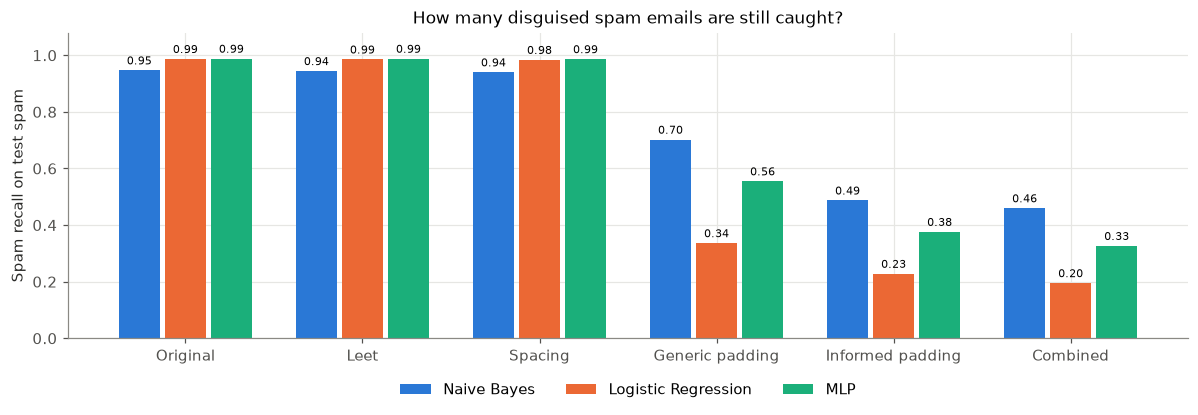

Spam recall                      \
Model            Logistic Regression     MLP Naive Bayes   
Attack                                                     
Original                      0.9874  0.9885      0.9472   
Leet                          0.9857  0.9883      0.9448   
Spacing                       0.9842  0.9869      0.9403   
Generic padding               0.3365  0.5552      0.7022   
Informed padding              0.2283  0.3764      0.4874   
Combined                      0.1954  0.3267      0.4599   

                 Recall on emails with targeted words                      
Model                             Logistic Regression     MLP Naive Bayes  
Attack                                                                     
Original                                       0.9928  0.9940      0.9716  
Leet                                           0.9902  0.9937      0.9678  
Spacing                                        0.9880  0.9915      0.9612  
Generic padding                                0.4699  0.7216      0.8414  
Informed padding                               0.3205  0.5116      0.6329  
Combined                                       0.2698  0.4382      0.5913

In [19]:
ATTACKS = ["Original", "Leet", "Spacing", "Generic padding", "Informed padding", "Combined"]
spam_test = test_df.loc[test_df["label"] == 1, "text"].tolist()

def attacked_matrix(attack, seed=SEED, n_pad=30):
    rng = random.Random(seed)
    return vectorizer.transform([clean(disguise(t, attack, rng, n_pad)) for t in spam_test])

touched = np.array([bool(SPAM_RE.search(t)) for t in spam_test])   # spam emails that contain a targeted word
print(f"{touched.mean():.1%} of test spam contains at least one of the {len(SPAM_WORDS)} targeted spam words")
attack_rows = []
for attack in ATTACKS:
    Xa = attacked_matrix(attack)
    for name, m in models.items():
        pred = m.predict(Xa)
        attack_rows.append({"Attack": attack, "Model": name, "Spam recall": pred.mean(),
                            "Recall on emails with targeted words": pred[touched].mean()})
attack_results = pd.DataFrame(attack_rows)
attack_results.to_csv(RES / "attack_results.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 3.9))
w = 0.26
for i, name in enumerate(models):
    vals = attack_results[attack_results["Model"] == name]["Spam recall"].values
    bars = ax.bar(np.arange(len(ATTACKS)) + (i - 1) * w, vals, w - 0.03, color=MODEL_COLORS[name], label=name)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in vals], fontsize=7.5, padding=2)
ax.set_xticks(np.arange(len(ATTACKS)), ATTACKS); ax.set_ylim(0, 1.08); ax.set_ylabel("Spam recall on test spam")
ax.set_title("How many disguised spam emails are still caught?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
fig.tight_layout(); save(fig, "fig_attacks")
attack_results.pivot(index="Attack", columns="Model", values=["Spam recall", "Recall on emails with targeted words"]).loc[ATTACKS].round(4)

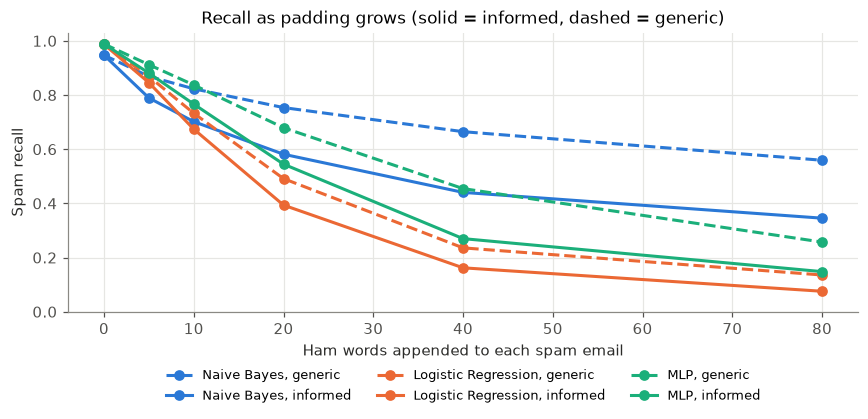

In [20]:
# Attack strength: number of padding words
pad_rows = []
for n_pad in [0, 5, 10, 20, 40, 80]:
    for attack in ["Generic padding", "Informed padding"]:
        Xa = attacked_matrix(attack, n_pad=n_pad)
        for name, m in models.items():
            pad_rows.append({"Padding words": n_pad, "Attack": attack, "Model": name, "Spam recall": m.predict(Xa).mean()})
pad_curve = pd.DataFrame(pad_rows)
pad_curve.to_csv(RES / "padding_curve.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
for name in models:
    for attack, ls in [("Generic padding", "--"), ("Informed padding", "-")]:
        d = pad_curve[(pad_curve["Model"] == name) & (pad_curve["Attack"] == attack)]
        ax.plot(d["Padding words"], d["Spam recall"], ls, marker="o", ms=6, lw=2, color=MODEL_COLORS[name],
                label=f"{name}, {attack.split()[0].lower()}")
ax.set_xlabel("Ham words appended to each spam email"); ax.set_ylabel("Spam recall"); ax.set_ylim(0, 1.03)
ax.set_title("Recall as padding grows (solid = informed, dashed = generic)")
ax.legend(fontsize=8.5, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.16))
fig.tight_layout(); save(fig, "fig_padding_curve")

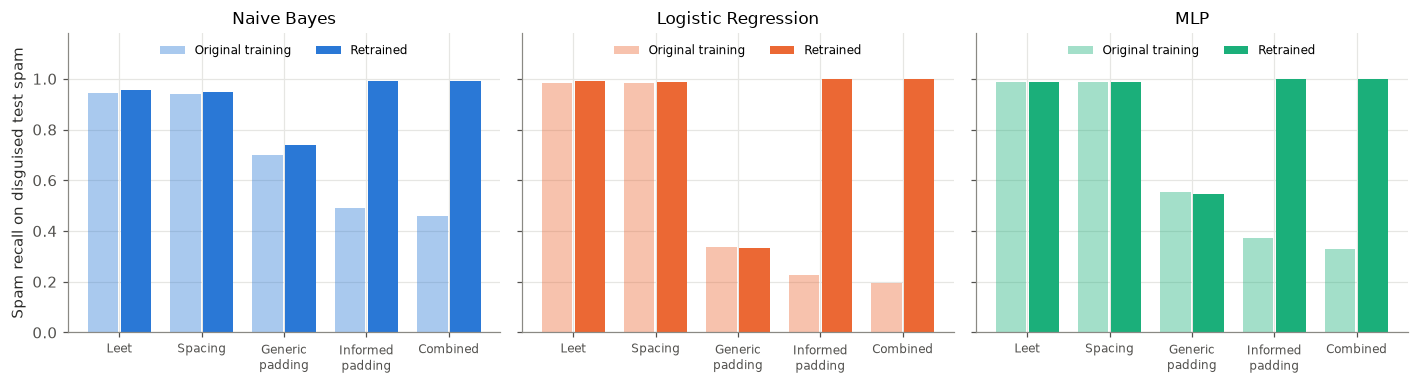

Clean test F1  \
Model               Version                                        
Naive Bayes         Original training                     0.9667   
                    Retrained with disguised spam         0.9694   
Logistic Regression Original training                     0.9845   
                    Retrained with disguised spam         0.9838   
MLP                 Original training                     0.9866   
                    Retrained with disguised spam         0.9859   

                                                   Clean test FPR    Leet  \
Model               Version                                                 
Naive Bayes         Original training                      0.0125  0.9450   
                    Retrained with disguised spam          0.0165  0.9567   
Logistic Regression Original training                      0.0186  0.9852   
                    Retrained with disguised spam          0.0219  0.9899   
MLP                 Original training                      0.0153  0.9881   
                    Retrained with disguised spam          0.0153  0.9884   

                                                   Spacing  Generic padding  \
Model               Version                                                   
Naive Bayes         Original training               0.9403           0.6988   
                    Retrained with disguised spam   0.9494           0.7393   
Logistic Regression Original training               0.9842           0.3367   
                    Retrained with disguised spam   0.9891           0.3315   
MLP                 Original training               0.9869           0.5543   
                    Retrained with disguised spam   0.9866           0.5479   

                                                   Informed padding  Combined  
Model               Version                                                    
Naive Bayes         Original training                        0.4910    0.4597  
                    Retrained with disguised spam            0.9901    0.9899  
Logistic Regression Original training                        0.2276    0.1950  
                    Retrained with disguised spam            0.9988    0.9988  
MLP                 Original training                        0.3741    0.3307  
                    Retrained with disguised spam            0.9974    0.9976

In [21]:
# First attempt at a fix: retrain each model with one disguised copy of every training spam email (random attack type).
# Note: the copies use the SAME word lists as the test attacks, so this only shows what happens when the attacker's words are known.
rng = random.Random(7)
train_attacks = ["Leet", "Spacing", "Informed padding", "Combined"]
aug_text = [clean(disguise(t, rng.choice(train_attacks), rng)) for t in train_df.loc[train_df["label"] == 1, "text"]]
X_aug = np.random.RandomState(SEED).permutation(X_train.shape[0] + len(aug_text))
X_train_aug = vstack([X_train, vectorizer.transform(aug_text)]).tocsr()[X_aug]
y_train_aug = np.concatenate([y_train, np.ones(len(aug_text), dtype=int)])[X_aug]

hardened = {"Naive Bayes": MultinomialNB(alpha=best_alpha).fit(X_train_aug, y_train_aug),
            "Logistic Regression": LogisticRegression(C=best_C, max_iter=3000).fit(X_train_aug, y_train_aug),
            "MLP": train_mlp(best_hidden, 1e-4, X_train_aug, y_train_aug, fixed_epochs=mlp_runs[best_hidden]["best_epoch"])[0]}

def_rows = []
for name in models:
    for version, m in [("Original training", models[name]), ("Retrained with disguised spam", hardened[name])]:
        s = scores(y_test, m.predict_proba(X_test)[:, 1])
        row = {"Model": name, "Version": version, "Clean test F1": s["F1"], "Clean test FPR": s["FPR (ham flagged)"]}
        for attack in ATTACKS[1:]:
            row[attack] = m.predict(attacked_matrix(attack, seed=SEED + 1)).mean()
        def_rows.append(row)
defense = pd.DataFrame(def_rows).set_index(["Model", "Version"])
defense.to_csv(RES / "defense_results.csv")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, name in zip(axes, models):
    before = defense.loc[(name, "Original training"), ATTACKS[1:]].values.astype(float)
    after = defense.loc[(name, "Retrained with disguised spam"), ATTACKS[1:]].values.astype(float)
    x = np.arange(len(ATTACKS) - 1)
    ax.bar(x - 0.2, before, 0.37, color=MODEL_COLORS[name], alpha=0.4, label="Original training")
    ax.bar(x + 0.2, after, 0.37, color=MODEL_COLORS[name], label="Retrained")
    ax.set_xticks(x, [a.replace(" padding", "\npadding") for a in ATTACKS[1:]], fontsize=8)
    ax.set_title(name); ax.set_ylim(0, 1.18); ax.legend(loc="upper center", ncol=2, fontsize=8)
axes[0].set_ylabel("Spam recall on disguised test spam")
fig.tight_layout(); save(fig, "fig_defense")
defense.round(4)

## 9. Fixing the padding weakness
Section 8 showed that adding ham words to spam fools every model, and that retraining with one fixed word list only protects against that list. We test two fixes:

* **Fix 1 – score the email in 50-word pieces.** Each email is cut into pieces of 50 words (a last piece under 25 words is joined to the one before). Every piece gets its own spam score and the email's score is the **highest** piece score, so added words cannot dilute the spam piece. The models are retrained on 50-word pieces so they know what a short piece of normal email looks like.
* **Fix 2 – train with randomly padded spam.** Every training spam email gets one extra copy with 10–80 words added at the end, drawn at random from the most ham-typical training words. **None of the words used in the tests are in this pool**, so the test checks whether the model learned the trick or only the words.
* **Fix 1 + 2** – both together.

For a fair comparison every fixed model's threshold is chosen on the **validation** set so that it flags the same share of legitimate email as the original model. Only the test set is used for the results.

In [22]:
CHUNK, MIN_LAST = 50, 25

def split_chunks(text):
    # Pieces of 50 words; a leftover piece shorter than 25 words is joined to the piece before it
    w = text.split()
    parts = [w[i:i + CHUNK] for i in range(0, len(w), CHUNK)] or [[]]
    if len(parts) > 1 and len(parts[-1]) < MIN_LAST:
        last = parts.pop()
        parts[-1] = parts[-1] + last
    return [" ".join(p) for p in parts]

def chunk_proba(model, texts):
    # Spam score of an email = the highest spam score of any of its pieces
    owner, pieces = [], []
    for i, t in enumerate(texts):
        for c in split_chunks(t):
            owner.append(i); pieces.append(c)
    p = model.predict_proba(vectorizer.transform(pieces))[:, 1]
    out = np.zeros(len(texts)); np.maximum.at(out, np.array(owner), p)
    return out

def chunk_training_set(texts, labels):
    pieces, ys = [], []
    for t, y in zip(texts, labels):
        for c in split_chunks(t):
            pieces.append(c); ys.append(y)
    X = vectorizer.transform(pieces); ys = np.array(ys)
    order = np.random.RandomState(SEED).permutation(X.shape[0])
    return X[order], ys[order]

def fit_three(X, y, label):
    t0 = time.time()
    fitted = {"Naive Bayes": MultinomialNB(alpha=best_alpha).fit(X, y),
              "Logistic Regression": LogisticRegression(C=best_C, max_iter=3000).fit(X, y),
              "MLP": train_mlp(best_hidden, 1e-4, X, y, fixed_epochs=mlp_runs[best_hidden]["best_epoch"])[0]}
    print(f"{label}: trained on {X.shape[0]:,} rows in {time.time() - t0:.0f} s")
    return fitted

print("Example:", [len(c.split()) for c in split_chunks(" ".join(["w"] * 120))], "words per piece for a 120-word email")
Xc, yc = chunk_training_set(train_df["text"].tolist(), y_train)
fix1 = fit_three(Xc, yc, "Fix 1 (models trained on 50-word pieces)")

Example: [50, 70] words per piece for a 120-word email


Fix 1 (models trained on 50-word pieces): trained on 429,462 rows in 151 s


In [23]:
# Fix 2: pool = the 500 most ham-typical training words, minus every word used by the test attacks
ok_ham = np.where((rate_ham >= 0.002) & (words != "num"))[0]
ham_ranked = list(words[ok_ham[np.argsort(log_ratio[ok_ham])]])
POOL = [w for w in ham_ranked[:500] if w not in set(HAM_WORDS) | set(GENERIC_WORDS)]
print(f"Padding pool: {len(POOL)} words, e.g.", ", ".join(POOL[:12]))

rng_pad = np.random.RandomState(SEED)
spam_train = train_df.loc[train_df["label"] == 1, "text"].tolist()
padded_copies = [t + " " + " ".join(rng_pad.choice(POOL, size=rng_pad.randint(10, 81))) for t in spam_train]
print("Example training copy (end):", "…", padded_copies[0][-160:])

X_pad = vstack([X_train, vectorizer.transform(padded_copies)]).tocsr()
y_pad = np.concatenate([y_train, np.ones(len(padded_copies), dtype=int)])
order_pad = np.random.RandomState(SEED).permutation(X_pad.shape[0])
fix2 = fit_three(X_pad[order_pad], y_pad[order_pad], "Fix 2 (original emails + padded spam copies)")

Xc2, yc2 = chunk_training_set(train_df["text"].tolist() + padded_copies,
                              np.concatenate([y_train, np.ones(len(padded_copies), dtype=int)]))
fix12 = fit_three(Xc2, yc2, "Fix 1 + 2 (pieces of original emails + padded copies)")

Padding pool: 467 words, e.g. zvllln, estoppel, ees, counterparty, smsbmo, ena, mmbtu, enforceable, steffes, uai, transwestern, counterparties


Example training copy (end): … rdinate replaced darren replaced nominations diane skilling lavorato kevin tariff deliveries module calger contributed hourly ene lunch approaches stanford perl


Fix 2 (original emails + padded spam copies): trained on 129,074 rows in 44 s


Fix 1 + 2 (pieces of original emails + padded copies): trained on 618,042 rows in 204 s


In [24]:
VERSIONS = {"Original": (models, False), "Fix 1: 50-word pieces": (fix1, True),
            "Fix 2: random padding": (fix2, False), "Fix 1 + 2": (fix12, True)}
FIX_ATTACKS = ["Generic padding", "Informed padding", "Combined"]
rng_eval = {a: random.Random(SEED + 2) for a in FIX_ATTACKS}
fix_attack_text = {a: [clean(disguise(t, a, rng_eval[a])) for t in spam_test] for a in FIX_ATTACKS}
val_ham_text = val_df.loc[val_df["label"] == 0, "text"].tolist()
test_text = test_df["text"].tolist()

def version_proba(m, chunked, texts=None, X=None):
    if chunked:
        return chunk_proba(m, texts)
    return m.predict_proba(X if X is not None else vectorizer.transform(texts))[:, 1]

fix_rows, fix_thresholds = [], {}
for name in models:
    target_fpr = (models[name].predict_proba(X_val[y_val == 0])[:, 1] >= 0.5).mean()   # original model's validation FPR
    for version, (group, chunked) in VERSIONS.items():
        m = group[name]
        if version == "Original":
            thr = 0.5
        else:
            thr = float(np.quantile(version_proba(m, chunked, val_ham_text, X_val[y_val == 0] if not chunked else None), 1 - target_fpr))
        fix_thresholds[(name, version)] = thr
        s = scores(y_test, version_proba(m, chunked, test_text, None if chunked else X_test), threshold=thr)
        row = {"Model": name, "Version": version, "Threshold": thr, "Clean F1": s["F1"],
               "Clean spam recall": s["Recall"], "Clean FPR": s["FPR (ham flagged)"]}
        for a in FIX_ATTACKS:
            row[a] = (version_proba(m, chunked, fix_attack_text[a]) >= thr).mean()
        fix_rows.append(row)
fix_results = pd.DataFrame(fix_rows).set_index(["Model", "Version"])
fix_results.to_csv(RES / "fix_results.csv")
fix_results.round(4)

Threshold  Clean F1  \
Model               Version                                      
Naive Bayes         Original                  0.5000    0.9667   
                    Fix 1: 50-word pieces     0.9138    0.8642   
                    Fix 2: random padding     0.5369    0.9521   
                    Fix 1 + 2                 0.9232    0.8626   
Logistic Regression Original                  0.5000    0.9845   
                    Fix 1: 50-word pieces     0.9295    0.9358   
                    Fix 2: random padding     0.5502    0.9828   
                    Fix 1 + 2                 0.9550    0.9163   
MLP                 Original                  0.5000    0.9866   
                    Fix 1: 50-word pieces     0.9885    0.9223   
                    Fix 2: random padding     0.5115    0.9860   
                    Fix 1 + 2                 0.9925    0.9119   

                                           Clean spam recall  Clean FPR  \
Model               Version                                               
Naive Bayes         Original                          0.9472     0.0125   
                    Fix 1: 50-word pieces             0.7682     0.0097   
                    Fix 2: random padding             0.9188     0.0113   
                    Fix 1 + 2                         0.7665     0.0107   
Logistic Regression Original                          0.9874     0.0186   
                    Fix 1: 50-word pieces             0.8955     0.0185   
                    Fix 2: random padding             0.9847     0.0194   
                    Fix 1 + 2                         0.8617     0.0192   
MLP                 Original                          0.9885     0.0153   
                    Fix 1: 50-word pieces             0.8686     0.0151   
                    Fix 2: random padding             0.9872     0.0152   
                    Fix 1 + 2                         0.8530     0.0178   

                                           Generic padding  Informed padding  \
Model               Version                                                    
Naive Bayes         Original                        0.7013            0.4904   
                    Fix 1: 50-word pieces           0.6603            0.6034   
                    Fix 2: random padding           0.6445            0.4457   
                    Fix 1 + 2                       0.6521            0.5964   
Logistic Regression Original                        0.3369            0.2283   
                    Fix 1: 50-word pieces           0.6065            0.5939   
                    Fix 2: random padding           0.2971            0.1896   
                    Fix 1 + 2                       0.5852            0.5803   
MLP                 Original                        0.5576            0.3739   
                    Fix 1: 50-word pieces           0.6158            0.5838   
                    Fix 2: random padding           0.4949            0.2933   
                    Fix 1 + 2                       0.6182            0.5836   

                                           Combined  
Model               Version                          
Naive Bayes         Original                 0.4606  
                    Fix 1: 50-word pieces    0.6027  
                    Fix 2: random padding    0.4144  
                    Fix 1 + 2                0.5974  
Logistic Regression Original                 0.1943  
                    Fix 1: 50-word pieces    0.6360  
                    Fix 2: random padding    0.1573  
                    Fix 1 + 2                0.6172  
MLP                 Original                 0.3297  
                    Fix 1: 50-word pieces    0.6218  
                    Fix 2: random padding    0.2647  
                    Fix 1 + 2                0.6172

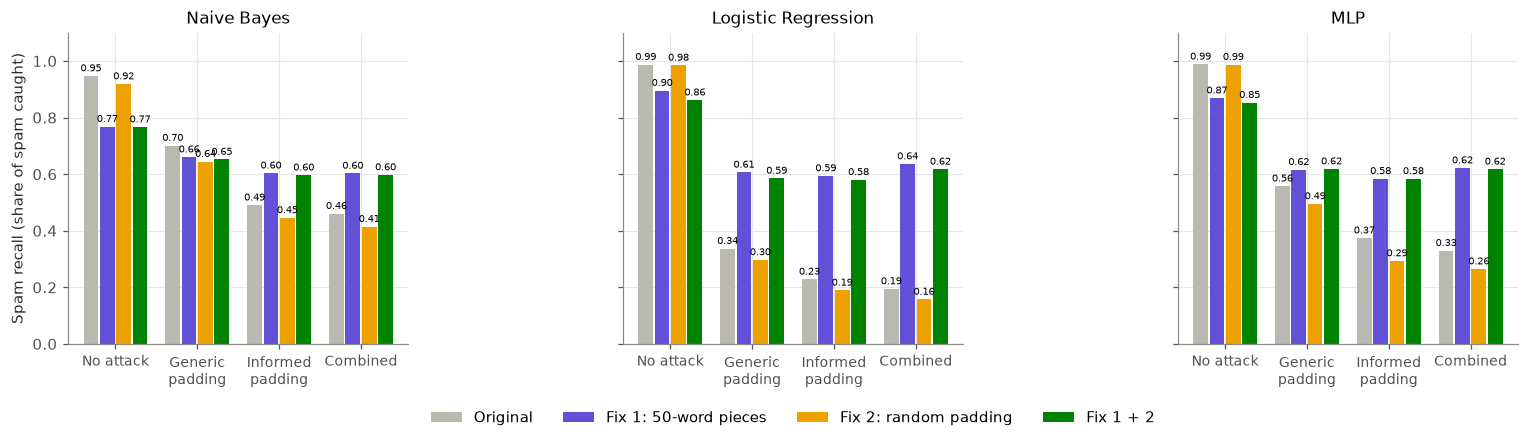

In [25]:
VERSION_COLORS = {"Original": "#b9b8b1", "Fix 1: 50-word pieces": "#6250d6", "Fix 2: random padding": "#eda100", "Fix 1 + 2": "#008300"}
groups = ["Clean spam recall"] + FIX_ATTACKS
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, name in zip(axes, models):
    for i, (version, col) in enumerate(VERSION_COLORS.items()):
        vals = fix_results.loc[(name, version), groups].values.astype(float)
        bars = ax.bar(np.arange(len(groups)) + (i - 1.5) * 0.2, vals, 0.18, color=col, label=version)
        ax.bar_label(bars, labels=[f"{v:.2f}" for v in vals], fontsize=6.5, padding=1.5)
    ax.set_xticks(np.arange(len(groups)), ["No attack", "Generic\npadding", "Informed\npadding", "Combined"], fontsize=9)
    ax.set_title(name); ax.set_ylim(0, 1.1)
axes[0].set_ylabel("Spam recall (share of spam caught)")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=4)
fig.tight_layout(); save(fig, "fig_fix_results")

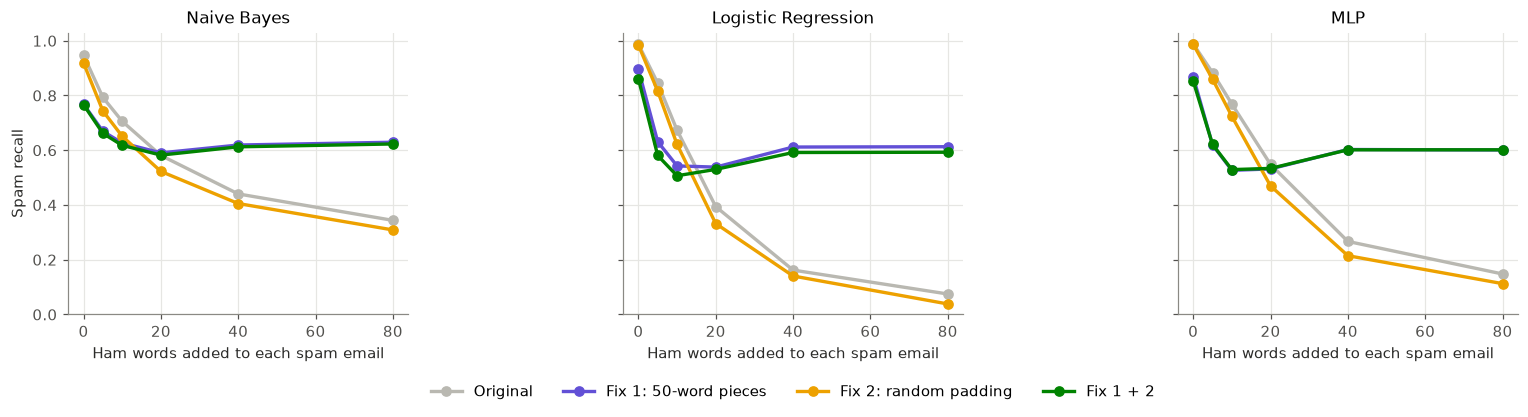

Model         Logistic Regression                                              \
Version                 Fix 1 + 2 Fix 1: 50-word pieces Fix 2: random padding   
Padding words                                                                   
0                           0.862                 0.895                 0.985   
5                           0.581                 0.631                 0.816   
10                          0.507                 0.543                 0.622   
20                          0.530                 0.538                 0.332   
40                          0.592                 0.612                 0.141   
80                          0.593                 0.613                 0.038   

Model                        MLP                                              \
Version       Original Fix 1 + 2 Fix 1: 50-word pieces Fix 2: random padding   
Padding words                                                                  
0                0.987     0.853                 0.869                 0.987   
5                0.845     0.621                 0.620                 0.860   
10               0.674     0.529                 0.527                 0.724   
20               0.394     0.534                 0.532                 0.470   
40               0.162     0.602                 0.603                 0.215   
80               0.075     0.602                 0.601                 0.113   

Model                  Naive Bayes                        \
Version       Original   Fix 1 + 2 Fix 1: 50-word pieces   
Padding words                                              
0                0.989       0.766                 0.768   
5                0.884       0.662                 0.669   
10               0.769       0.618                 0.627   
20               0.548       0.582                 0.590   
40               0.267       0.612                 0.619   
80               0.148       0.623                 0.629   

Model                                         
Version       Fix 2: random padding Original  
Padding words                                 
0                             0.919    0.947  
5                             0.743    0.793  
10                            0.651    0.706  
20                            0.523    0.581  
40                            0.405    0.440  
80                            0.309    0.344

In [26]:
# How each version holds up as more ham words are added (informed padding)
curve_rows = []
for n_pad in [0, 5, 10, 20, 40, 80]:
    rng = random.Random(SEED + 3)
    texts = [clean(disguise(t, "Informed padding", rng, n_pad)) for t in spam_test]
    Xw = vectorizer.transform(texts)
    for name in models:
        for version, (group, chunked) in VERSIONS.items():
            p = version_proba(group[name], chunked, texts, None if chunked else Xw)
            curve_rows.append({"Padding words": n_pad, "Model": name, "Version": version,
                               "Spam recall": (p >= fix_thresholds[(name, version)]).mean()})
fix_curve = pd.DataFrame(curve_rows)
fix_curve.to_csv(RES / "fix_padding_curve.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, name in zip(axes, models):
    for version, col in VERSION_COLORS.items():
        d = fix_curve[(fix_curve["Model"] == name) & (fix_curve["Version"] == version)]
        ax.plot(d["Padding words"], d["Spam recall"], "o-", color=col, lw=2.2, ms=6, label=version)
    ax.set_title(name); ax.set_xlabel("Ham words added to each spam email"); ax.set_ylim(0, 1.03)
axes[0].set_ylabel("Spam recall")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4)
fig.tight_layout(); save(fig, "fig_fix_curve")
fix_curve.pivot_table(index="Padding words", columns=["Model", "Version"], values="Spam recall").round(3)

In [1]:
# F1 under attack. The attacks change only the spam emails, so legitimate emails are flagged exactly as often
# as without an attack. F1 therefore follows directly from the attack recall and the false-positive rate:
# F1 = 2·TP / (2·TP + FP + FN). For the clean test set this formula reproduces the F1 values of Section 7.
import json
from pathlib import Path
import pandas as pd
RES_DIR = Path.cwd() / "results"
info = json.loads((RES_DIR / "summary.json").read_text())
n_spam = info["n_test_spam"]; n_ham = info["split"]["Emails"]["Test"] - n_spam

def f1_from(recall, fpr):
    tp, fn, fp = recall * n_spam, (1 - recall) * n_spam, fpr * n_ham
    return 2 * tp / (2 * tp + fp + fn)

base = pd.read_csv(RES_DIR / "test_results.csv", index_col=0)
att = pd.read_csv(RES_DIR / "attack_results.csv")
att["F1"] = [f1_from(r, base.loc[m, "FPR (ham flagged)"]) for r, m in zip(att["Spam recall"], att["Model"])]
f1_attacks = att.pivot(index="Attack", columns="Model", values="F1").loc[["Original", "Leet", "Spacing", "Generic padding", "Informed padding", "Combined"]]

fixes = pd.read_csv(RES_DIR / "fix_results.csv")
for a in ["Generic padding", "Informed padding", "Combined"]:
    fixes[f"F1 · {a}"] = [f1_from(r, f) for r, f in zip(fixes[a], fixes["Clean FPR"])]
f1_fixes = fixes.set_index(["Model", "Version"])[["Clean F1", "F1 · Generic padding", "F1 · Informed padding", "F1 · Combined"]]
f1_fixes.to_csv(RES_DIR / "f1_under_attack.csv")

print("F1 of the original models under each attack:")
display(f1_attacks.round(3))
print("F1 of each fix (clean test set and under each padding attack):")
display(f1_fixes.round(3))

F1 of the original models under each attack:


Model,Logistic Regression,MLP,Naive Bayes
Attack,,,
Original,0.985,0.987,0.967
Leet,0.984,0.987,0.965
Spacing,0.983,0.986,0.963
Generic padding,0.497,0.707,0.819
Informed padding,0.366,0.541,0.650
Combined,0.322,0.487,0.625


F1 of each fix (clean test set and under each padding attack):


Clean F1  F1 · Generic padding  \
Model               Version                                                 
Naive Bayes         Original                  0.967                 0.818   
                    Fix 1: 50-word pieces     0.864                 0.791   
                    Fix 2: random padding     0.952                 0.778   
                    Fix 1 + 2                 0.863                 0.784   
Logistic Regression Original                  0.985                 0.497   
                    Fix 1: 50-word pieces     0.936                 0.746   
                    Fix 2: random padding     0.983                 0.451   
                    Fix 1 + 2                 0.916                 0.730   
MLP                 Original                  0.987                 0.709   
                    Fix 1: 50-word pieces     0.922                 0.755   
                    Fix 2: random padding     0.986                 0.655   
                    Fix 1 + 2                 0.912                 0.756   

                                           F1 · Informed padding  \
Model               Version                                        
Naive Bayes         Original                               0.653   
                    Fix 1: 50-word pieces                  0.748   
                    Fix 2: random padding                  0.612   
                    Fix 1 + 2                              0.742   
Logistic Regression Original                               0.366   
                    Fix 1: 50-word pieces                  0.737   
                    Fix 2: random padding                  0.314   
                    Fix 1 + 2                              0.726   
MLP                 Original                               0.538   
                    Fix 1: 50-word pieces                  0.730   
                    Fix 2: random padding                  0.448   
                    Fix 1 + 2                              0.729   

                                           F1 · Combined  
Model               Version                               
Naive Bayes         Original                       0.625  
                    Fix 1: 50-word pieces          0.748  
                    Fix 2: random padding          0.581  
                    Fix 1 + 2                      0.743  
Logistic Regression Original                       0.320  
                    Fix 1: 50-word pieces          0.769  
                    Fix 2: random padding          0.267  
                    Fix 1 + 2                      0.754  
MLP                 Original                       0.490  
                    Fix 1: 50-word pieces          0.760  
                    Fix 2: random padding          0.414  
                    Fix 1 + 2                      0.755

## 10. Save models and results

In [27]:
joblib.dump({"vectorizer": vectorizer, "naive_bayes": nb, "logistic_regression": lr, "mlp": mlp}, MOD / "spamshield_models.joblib", compress=3)
summary = {
    "datasets": {"raw": raw_counts.to_dict(), "clean": clean_counts.to_dict()},
    "cleaning_steps": cleaning_steps.to_dict("records"), "split": split_table.to_dict(),
    "tfidf_features": int(X_train.shape[1]), "best_alpha": float(best_alpha), "best_C": float(best_C),
    "best_hidden": int(best_hidden), "mlp_best_epoch": int(mlp_runs[best_hidden]["best_epoch"]),
    "nb_grid": nb_grid.to_dict("records"), "lr_grid": lr_grid.to_dict("records"),
    "mlp_runs": {h: {"best_epoch": r["best_epoch"], "val_F1": float(r["val_F1"]), "time": r["time"],
                     "history": r["history"].to_dict("records")} for h, r in mlp_runs.items()},
    "size_curve": size_curve.to_dict("records"), "spam_words": SPAM_WORDS, "ham_words": HAM_WORDS,
    "touched_share": float(touched.mean()), "n_test_spam": len(spam_test), "pool_size": len(POOL), "pool_examples": POOL[:20],
}
(RES / "summary.json").write_text(json.dumps(summary, indent=1, default=str))

def predict_email(text, model=models[best_name]):
    p = model.predict_proba(vectorizer.transform([clean(text)]))[0, 1]
    return ("SPAM" if p >= 0.5 else "HAM"), round(float(p), 3)

for subject_body in ["Congratulations! You have won a $1,000 gift card. Click the link below to claim your prize before midnight.",
                     "Project meeting moved. Hi team, the meeting is moved to Thursday at 3 pm in room 204. Please bring your slides."]:
    print(predict_email(subject_body), "|", subject_body[:60], "...")

('SPAM', 0.994) | Congratulations! You have won a $1,000 gift card. Click the  ...
('HAM', 0.0) | Project meeting moved. Hi team, the meeting is moved to Thur ...


## Summary
- Three models were trained on 122,850 unique emails from TREC 2005, CEAS 2008 and Enron-Spam, and compared on the same untouched test set.
- Section 7 compares accuracy, precision, recall, F1, ROC-AUC, the false-positive rate on ham, and speed.
- Section 8 shows that changing letters barely matters, but adding ham words fools every model; retraining with the attack's own word list fixes only that list.
- Section 9 tests two fixes: scoring 50-word pieces (works against any added words, but misses some normal spam at the same false-alarm rate) and training with randomly padded spam (protects only against words it has seen).
- Interpretation, limitations and conclusions are in the research paper.